## 2. トピックスII
### 2.7 適用例
#### 図2.2, 2.3

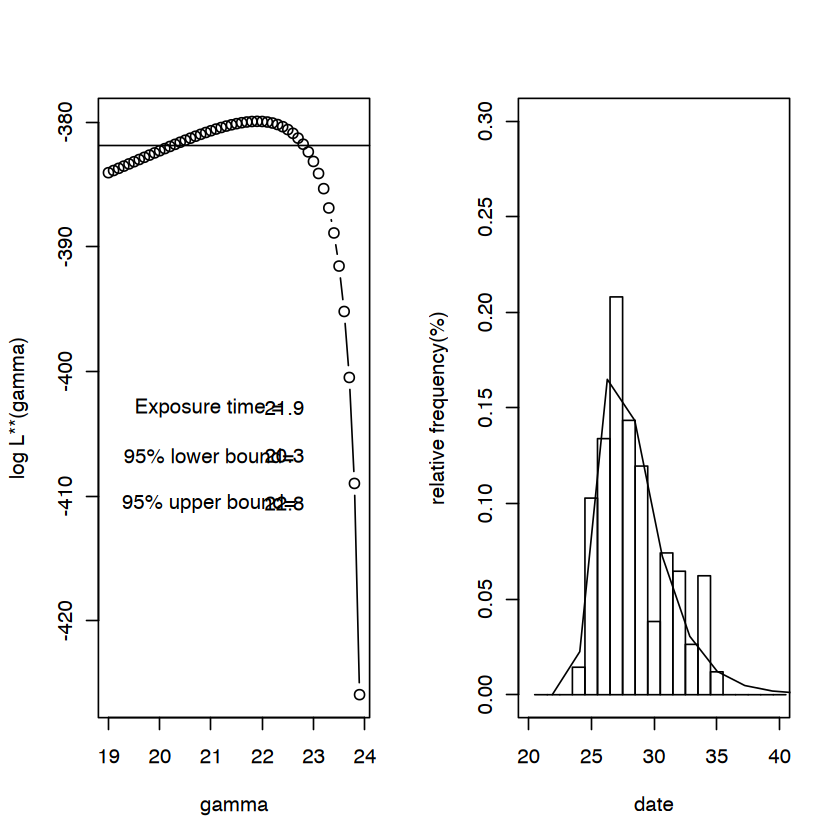

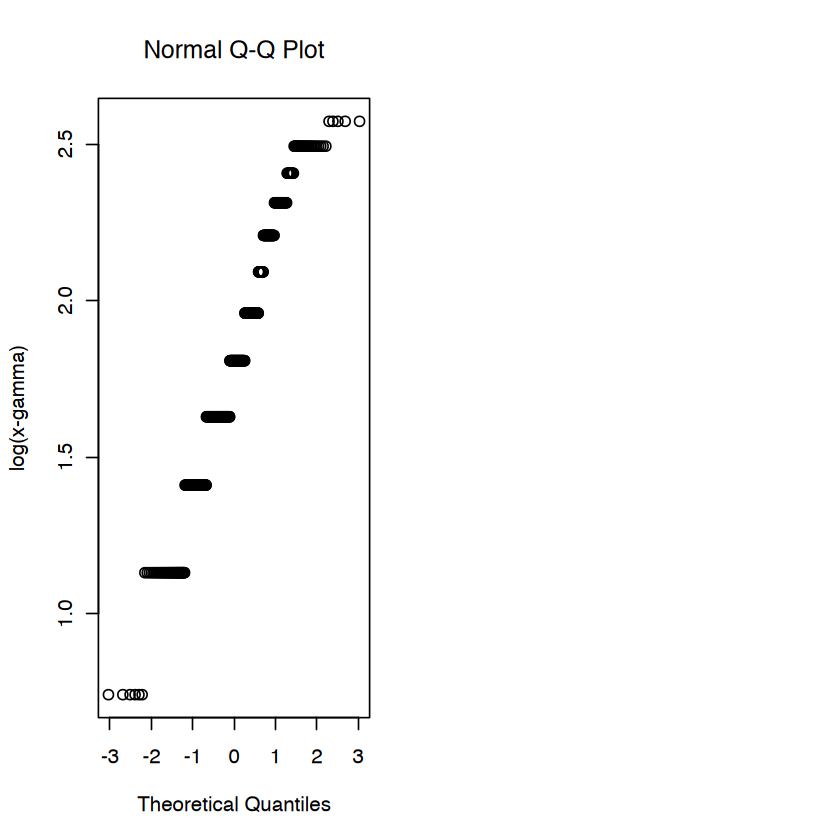

In [1]:
par(bg = "white")
# appendix B.1 (Figure 2.2, 2.3)
#
# Input: ts   = data vector
#        sta  = starting date
#        xmin = min of x-axis
#        xmax = max of x-axis
#        dens = max of y-axis
#        hh   = width adjustment factor for line search
# ----------------------- Example -----------------------
# H8 Okayama ken
ts<-c(rep(24,6), rep(25,43), rep(26,56), rep(27,87), rep(28,60), rep(29,50),
      rep(30,16), rep(31,31), rep(32,27), rep(33,11), rep(34,26), rep(35,5))
sta<-19; xmin<-20; xmax<-40; dens<-0.3; hh<-10
# -------------------------------------------------------
par(mfrow=c(1,2))
jj<-floor(min(ts*hh))-1; st<-sta*hh; q<-st:jj
ind<-(st:jj)/hh; n<-length(ts)
for (s in st:jj) {
  ss<-s/hh; y<-log(ts-ss); m1<-mean(y); v<-var(y)
  q[s-st+1]<-n*(log(v)+2*m1)*(-1/2)
}
plot(ind, q, type="b", pch=1, xlab="gamma", ylab="log L**(gamma)")
abline(h=max(q)-1.92); sol<-ind[q==max(q)]; pos<-(max(q)+min(q))/2
x1<-st+(jj-st)/5*2; x1<-x1/hh
x2<-st+(jj-st)/5*3.5; x2<-x2/hh
text(x1, pos, "Exposure time ="); text(x2, pos, sol)
low95<-min(ind[q>max(q)-1.92]); upp95<-max(ind[q>max(q)-1.92])
w<-(max(q)-pos)/6
text(x1, pos-w, "95% lower bound="); text(x2, pos-w, low95)
text(x1, pos-w*2, "95% upper bound="); text(x2, pos-w*2, upp95)
sk<-sum((ts-mean(ts))^3)/(sum((ts-mean(ts))^2))^1.5*sqrt(n)
mu<-mean(log(ts-sol))
sigma<-sqrt(var(log(ts-sol))*(n-1)/n)
linf<- -n/2*log(var(ts)*(n-1)/n)
lgn<-max(q)-n/2*(1+log(2*3.141593))
soln<-floor(sol*10)+1
z <- (sol*10:(xmax*10))/10
plot(z, dlnorm(z-sol, mu, sigma), type="l", xlim=c(xmin, xmax), ylim=c(0, dens),
     ylab="relative frequency(%)", xlab=" date ")
w <- (xmin:xmax)+0.5; h <- 1
r <- hist(ts, breaks=w, plot=F); k <- xmax-xmin
for (i in 1:k) {
  a <- c(w[i], w[i], w[i+1], w[i+1], w[i])
  b <- c(0, r$counts[i], r$counts[i], 0, 0); lines(a, b/n/h)
}
qqnorm(log(ts-sol), ylab="log(x-gamma)")


### 練習問題
#### 問題2.1

In [2]:
x <- c(rep(10, 1), rep(11, 2), rep(12, 15), rep(13, 22), rep(14, 17), rep(15, 10), rep(16, 2), rep(17, 5), rep(21, 1), rep(22, 1))
n <- length(x)

In [3]:
m <- function(g) {sum(log(x - g)) / n}
s <- function(g) {sqrt(sum((log(x - g) - m(g))^2)) / n}
l <- function(g) {- n*(m(g) + log(s(g))) - n/2*(1+log(2*pi))}
res <- optimize(l, (0: min(x)), maximum = TRUE)
g_mle <- res$maximum
g_mle

[1] 8.012718

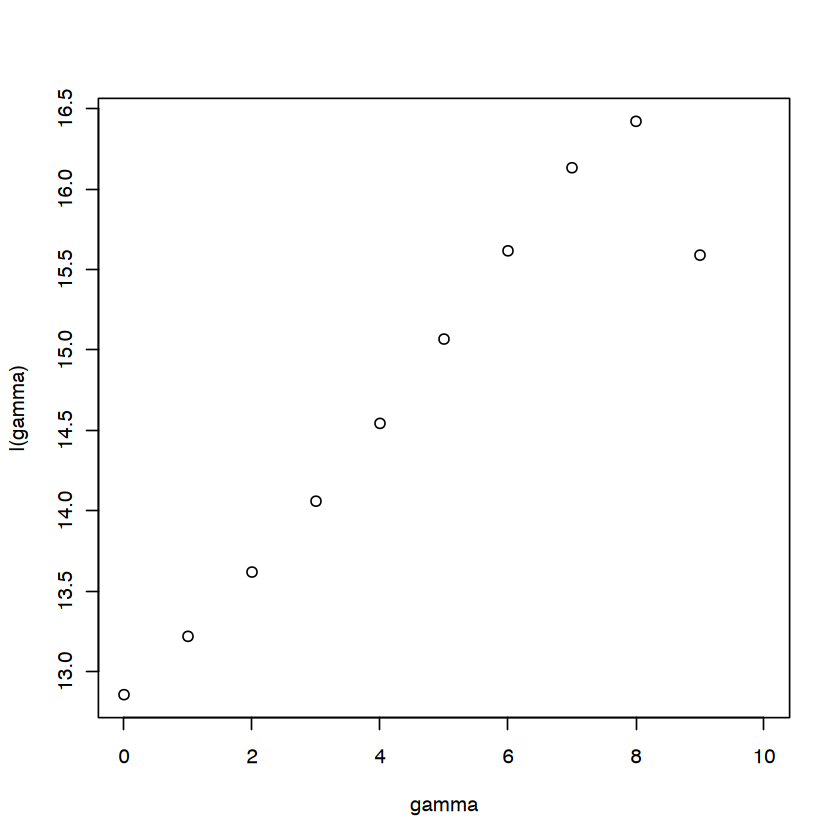

In [4]:
par(bg = "white")
plot(0:min(x), sapply(0:min(x), l), xlab = "gamma", ylab = "l(gamma)")

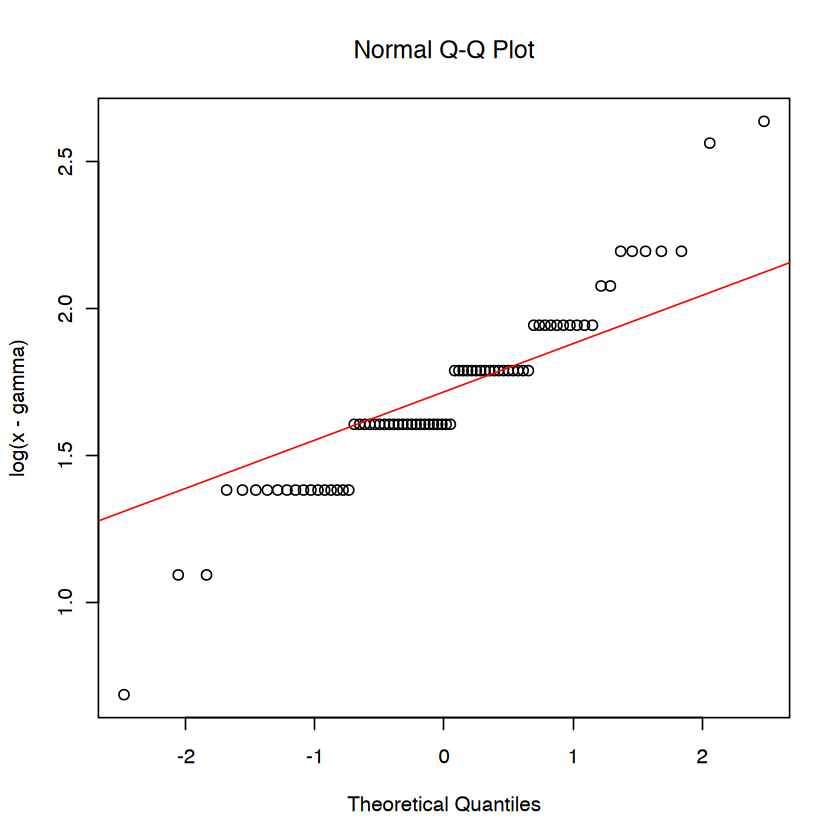

In [5]:
par(bg = "white")
qqnorm(log(x - g_mle), ylab = "log(x - gamma)")
qqline(log(x - g_mle), col="red")